In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math
import warnings


from sklearn.linear_model import LassoCV
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_regression


warnings.filterwarnings('ignore')

In [2]:
%store -r combined_df
combined_df


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
644,MS,F,19,R,GT3,T,2,3,services,other,...,5,4,2,1,2,5,4,10,11,10
645,MS,F,18,U,LE3,T,3,1,teacher,services,...,4,3,4,1,1,1,4,15,15,16
646,MS,F,18,U,GT3,T,1,1,other,other,...,1,1,1,1,1,5,6,11,12,9
647,MS,M,17,U,LE3,T,3,1,services,services,...,2,4,5,3,4,2,6,10,10,10


In [3]:
df = combined_df.reset_index(drop=True)


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      649 non-null    object
 1   sex         649 non-null    object
 2   age         649 non-null    int64 
 3   address     649 non-null    object
 4   famsize     649 non-null    object
 5   Pstatus     649 non-null    object
 6   Medu        649 non-null    int64 
 7   Fedu        649 non-null    int64 
 8   Mjob        649 non-null    object
 9   Fjob        649 non-null    object
 10  reason      649 non-null    object
 11  guardian    649 non-null    object
 12  traveltime  649 non-null    int64 
 13  studytime   649 non-null    int64 
 14  failures    649 non-null    int64 
 15  schoolsup   649 non-null    object
 16  famsup      649 non-null    object
 17  paid        649 non-null    object
 18  activities  649 non-null    object
 19  nursery     649 non-null    object
 20  higher    

In [5]:
print(df.isna().sum())

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64


In [6]:
df.columns.tolist()

['school',
 'sex',
 'age',
 'address',
 'famsize',
 'Pstatus',
 'Medu',
 'Fedu',
 'Mjob',
 'Fjob',
 'reason',
 'guardian',
 'traveltime',
 'studytime',
 'failures',
 'schoolsup',
 'famsup',
 'paid',
 'activities',
 'nursery',
 'higher',
 'internet',
 'romantic',
 'famrel',
 'freetime',
 'goout',
 'Dalc',
 'Walc',
 'health',
 'absences',
 'G1',
 'G2',
 'G3']

There are a lot of features. which ones are useful for the target variables? 

One way to check which ones are most important, Mutual informations is good for feature selection when we have mixed data types and when we have no idea about the type of linearity. 

In [7]:
df = df.drop(columns=["G1", "G2"])      

In [8]:
X = df.drop(columns="G3")
y = df["G3"]

In [9]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0)

In [10]:

X_train_encoded = X_train.copy()
cat_cols = X_train_encoded.select_dtypes(include=['object', 'category']).columns

encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
X_train_encoded[cat_cols] = encoder.fit_transform(X_train_encoded[cat_cols])

mi_scores = mutual_info_regression(X_train_encoded, y_train, random_state=0)
mi_scores = pd.Series(mi_scores, index=X_train.columns).sort_values(ascending=False)

print("Mutual Information Scores (Train Set):")
print(mi_scores)

Mutual Information Scores (Train Set):
failures      0.105721
absences      0.103178
Medu          0.097801
higher        0.080110
schoolsup     0.079519
freetime      0.055699
studytime     0.048492
Walc          0.045065
age           0.044401
Dalc          0.043131
traveltime    0.041161
Fjob          0.039192
Fedu          0.027682
school        0.021594
famsup        0.021175
internet      0.019736
goout         0.016936
Mjob          0.016313
health        0.010942
reason        0.001353
romantic      0.000000
famrel        0.000000
Pstatus       0.000000
nursery       0.000000
activities    0.000000
famsize       0.000000
sex           0.000000
address       0.000000
guardian      0.000000
paid          0.000000
dtype: float64


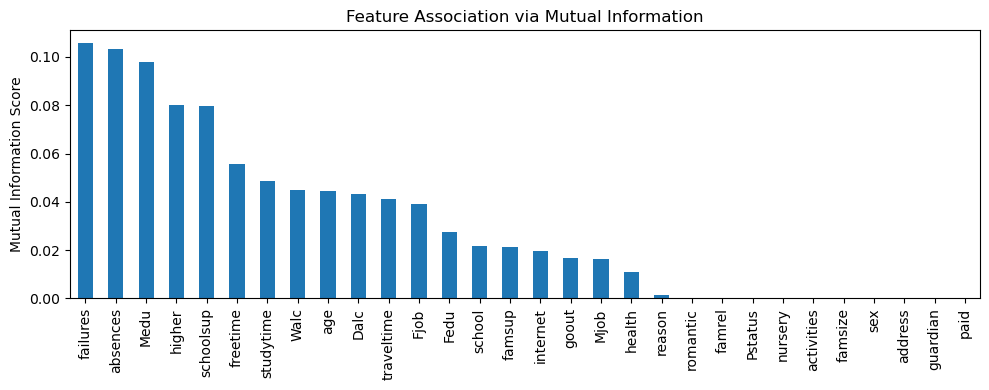

In [11]:

plt.figure(figsize=(10, 4))
mi_scores.plot(kind='bar')
plt.ylabel('Mutual Information Score')
plt.title('Feature Association via Mutual Information')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [12]:
# Set a threshold 
selected_features = mi_scores[mi_scores > 0.01].index.tolist()

print(selected_features)

['failures', 'absences', 'Medu', 'higher', 'schoolsup', 'freetime', 'studytime', 'Walc', 'age', 'Dalc', 'traveltime', 'Fjob', 'Fedu', 'school', 'famsup', 'internet', 'goout', 'Mjob', 'health']


Selecting the "Most associated" features to the Target Variable is generally the best approach to avoid overfitting and to avoid Multicolinearity.

The Question remains: how do i make sure these variables **['failures', 'absences', 'Medu', 'higher', 'schoolsup', 'freetime', 'studytime', 'Walc', 'age', 'Dalc', 'traveltime', 'Fjob', 'Fedu', 'school', 'famsup', 'internet', 'goout', 'Mjob', 'health']** are indeed the useful ones in the prediction model.

After some research on "ISLP" book and "To Explain or to Predict?" Article By Galit Shmueli, The best approches in this case are: 

- Visualization As a first layer, to get a glimpse of the real realtionship between the feature and the response.

- The Lasso, which automatically zeroes out coefficients for useless features.

- Random Forest feature importances, and comparing them with the Mutual Information scores. 

In [13]:
cat_cols = X.select_dtypes(include=['object']).columns.tolist()
cat_cols

['school',
 'sex',
 'address',
 'famsize',
 'Pstatus',
 'Mjob',
 'Fjob',
 'reason',
 'guardian',
 'schoolsup',
 'famsup',
 'paid',
 'activities',
 'nursery',
 'higher',
 'internet',
 'romantic']

In [14]:
con_cols = X.select_dtypes(include=['int','float']).columns.tolist()
con_cols

['age',
 'Medu',
 'Fedu',
 'traveltime',
 'studytime',
 'failures',
 'famrel',
 'freetime',
 'goout',
 'Dalc',
 'Walc',
 'health',
 'absences']

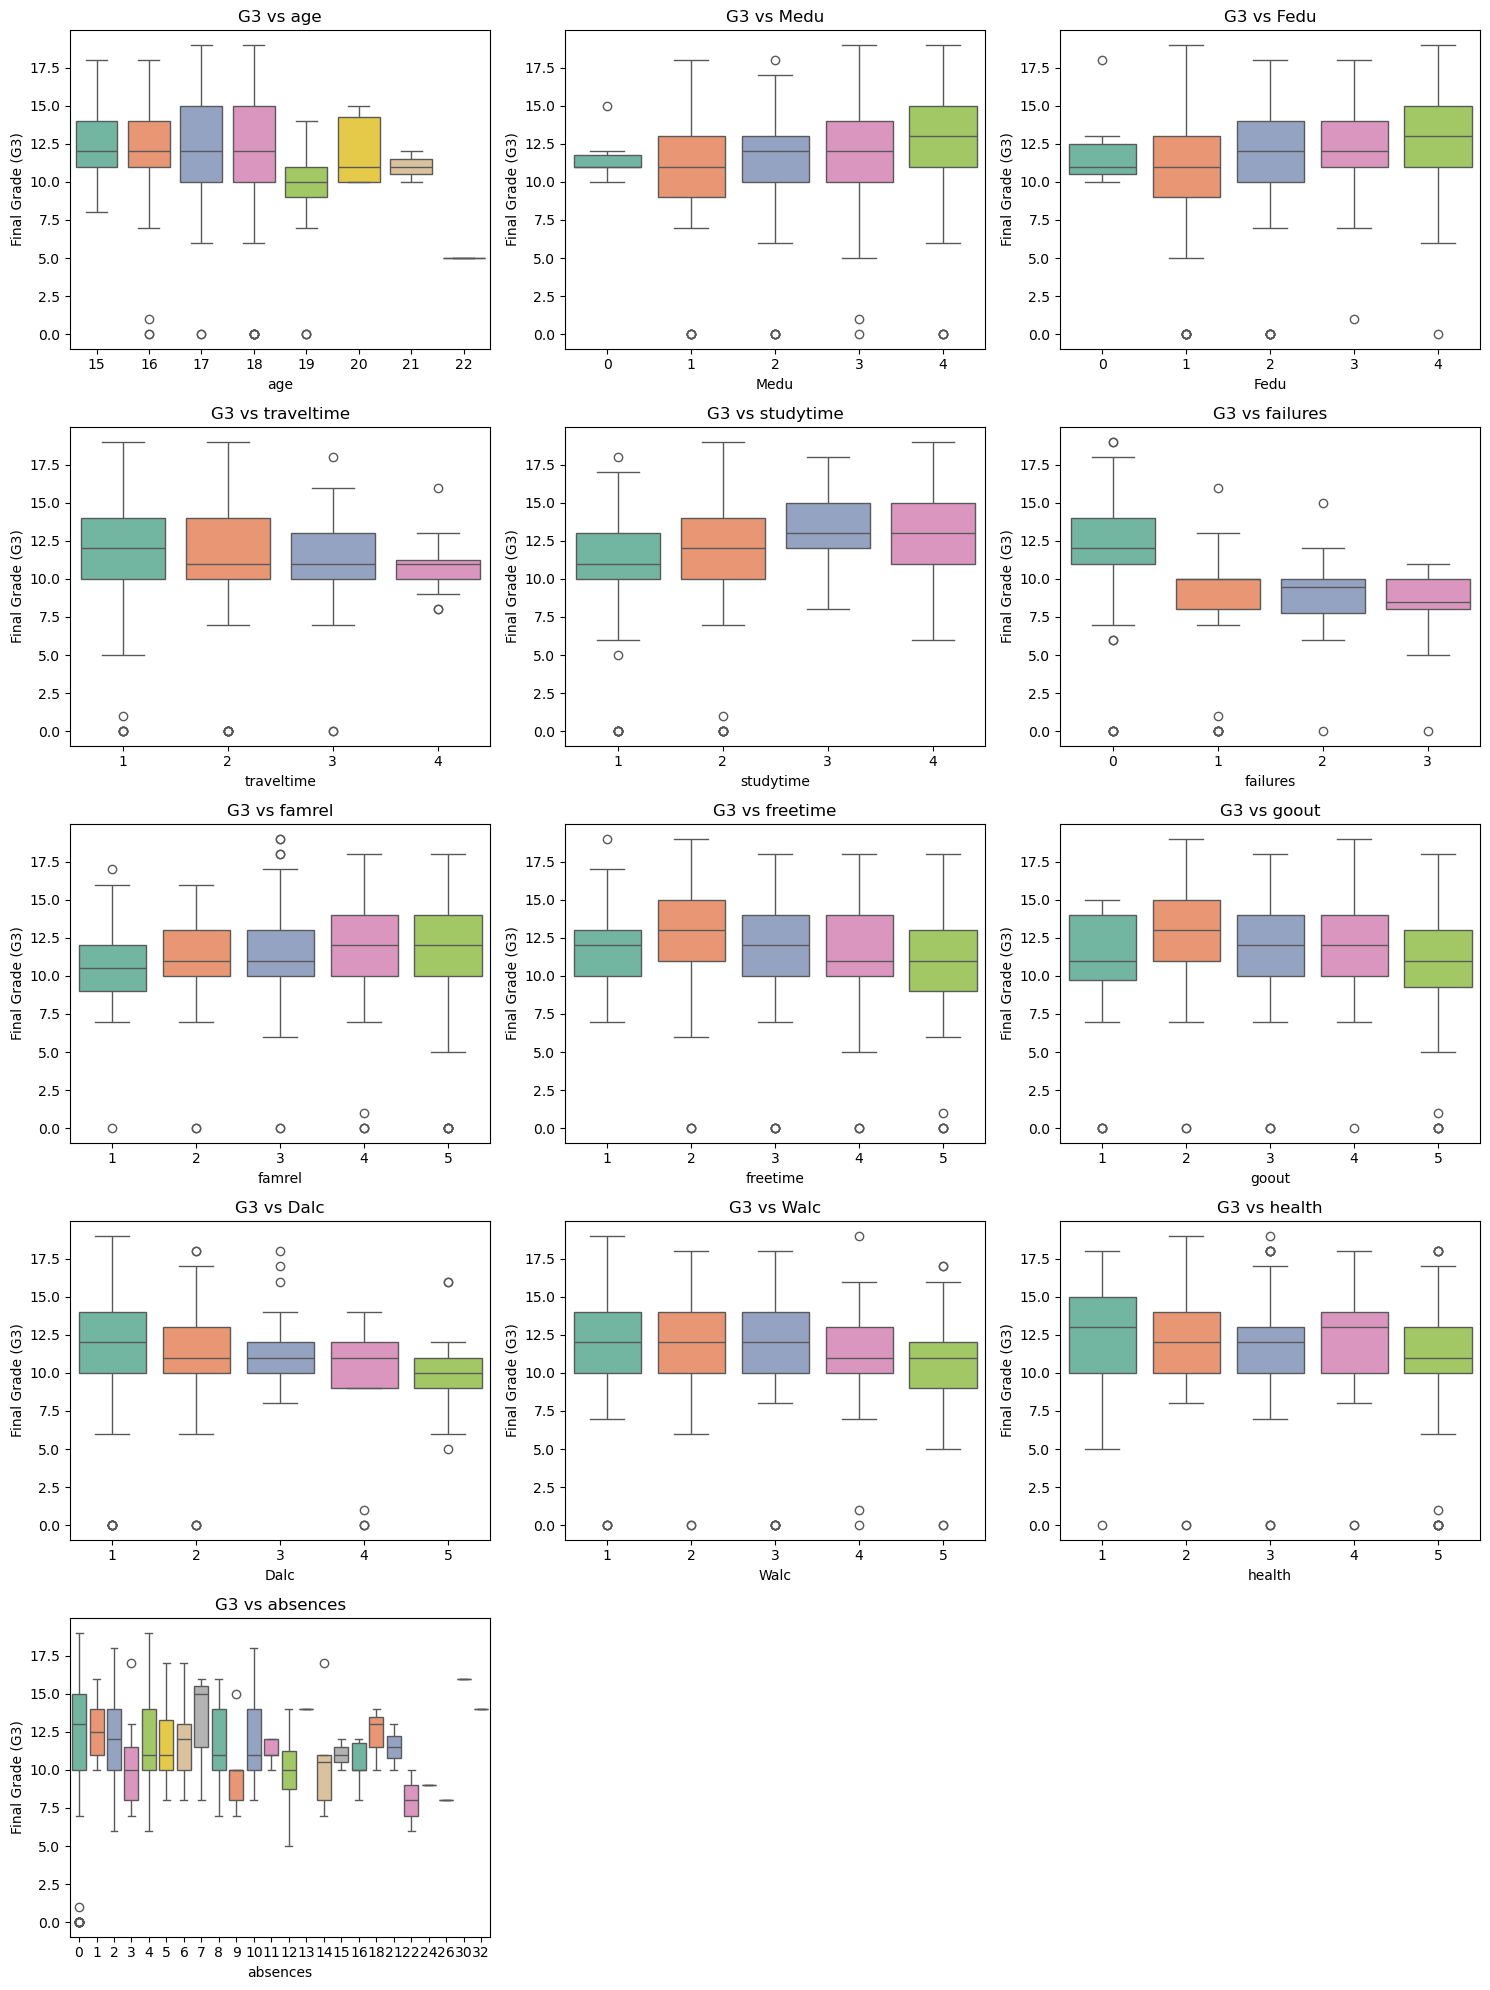

In [15]:


num_vars = [
    'age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 
    'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences'
]
cols = 3
rows = math.ceil(len(num_vars) / cols)
fig, axes = plt.subplots(rows, cols, figsize=(15, rows * 4))
axes = axes.flatten()  # Flatten the 2D array of axes for easy iteration
for i, var in enumerate(num_vars):
    sns.boxplot(x=var, y='G3', data=df, ax=axes[i], palette='Set2')
    axes[i].set_title(f'G3 vs {var}')
    axes[i].set_xlabel(var)
    axes[i].set_ylabel('Final Grade (G3)')

# Hide any unused subplots (since 13 doesn't divide evenly by 3, the last row will have 2 empty slots)
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


Visually we can see that : Travel Time , Study Time , Failure, famrel(quality of family relationships) , Dalc(workday alcohol consumption) and Absences Are pretty associated with the G3-The target Variable-.

All of them make sense, the more or less a value is, clearly affects the outcome G3.

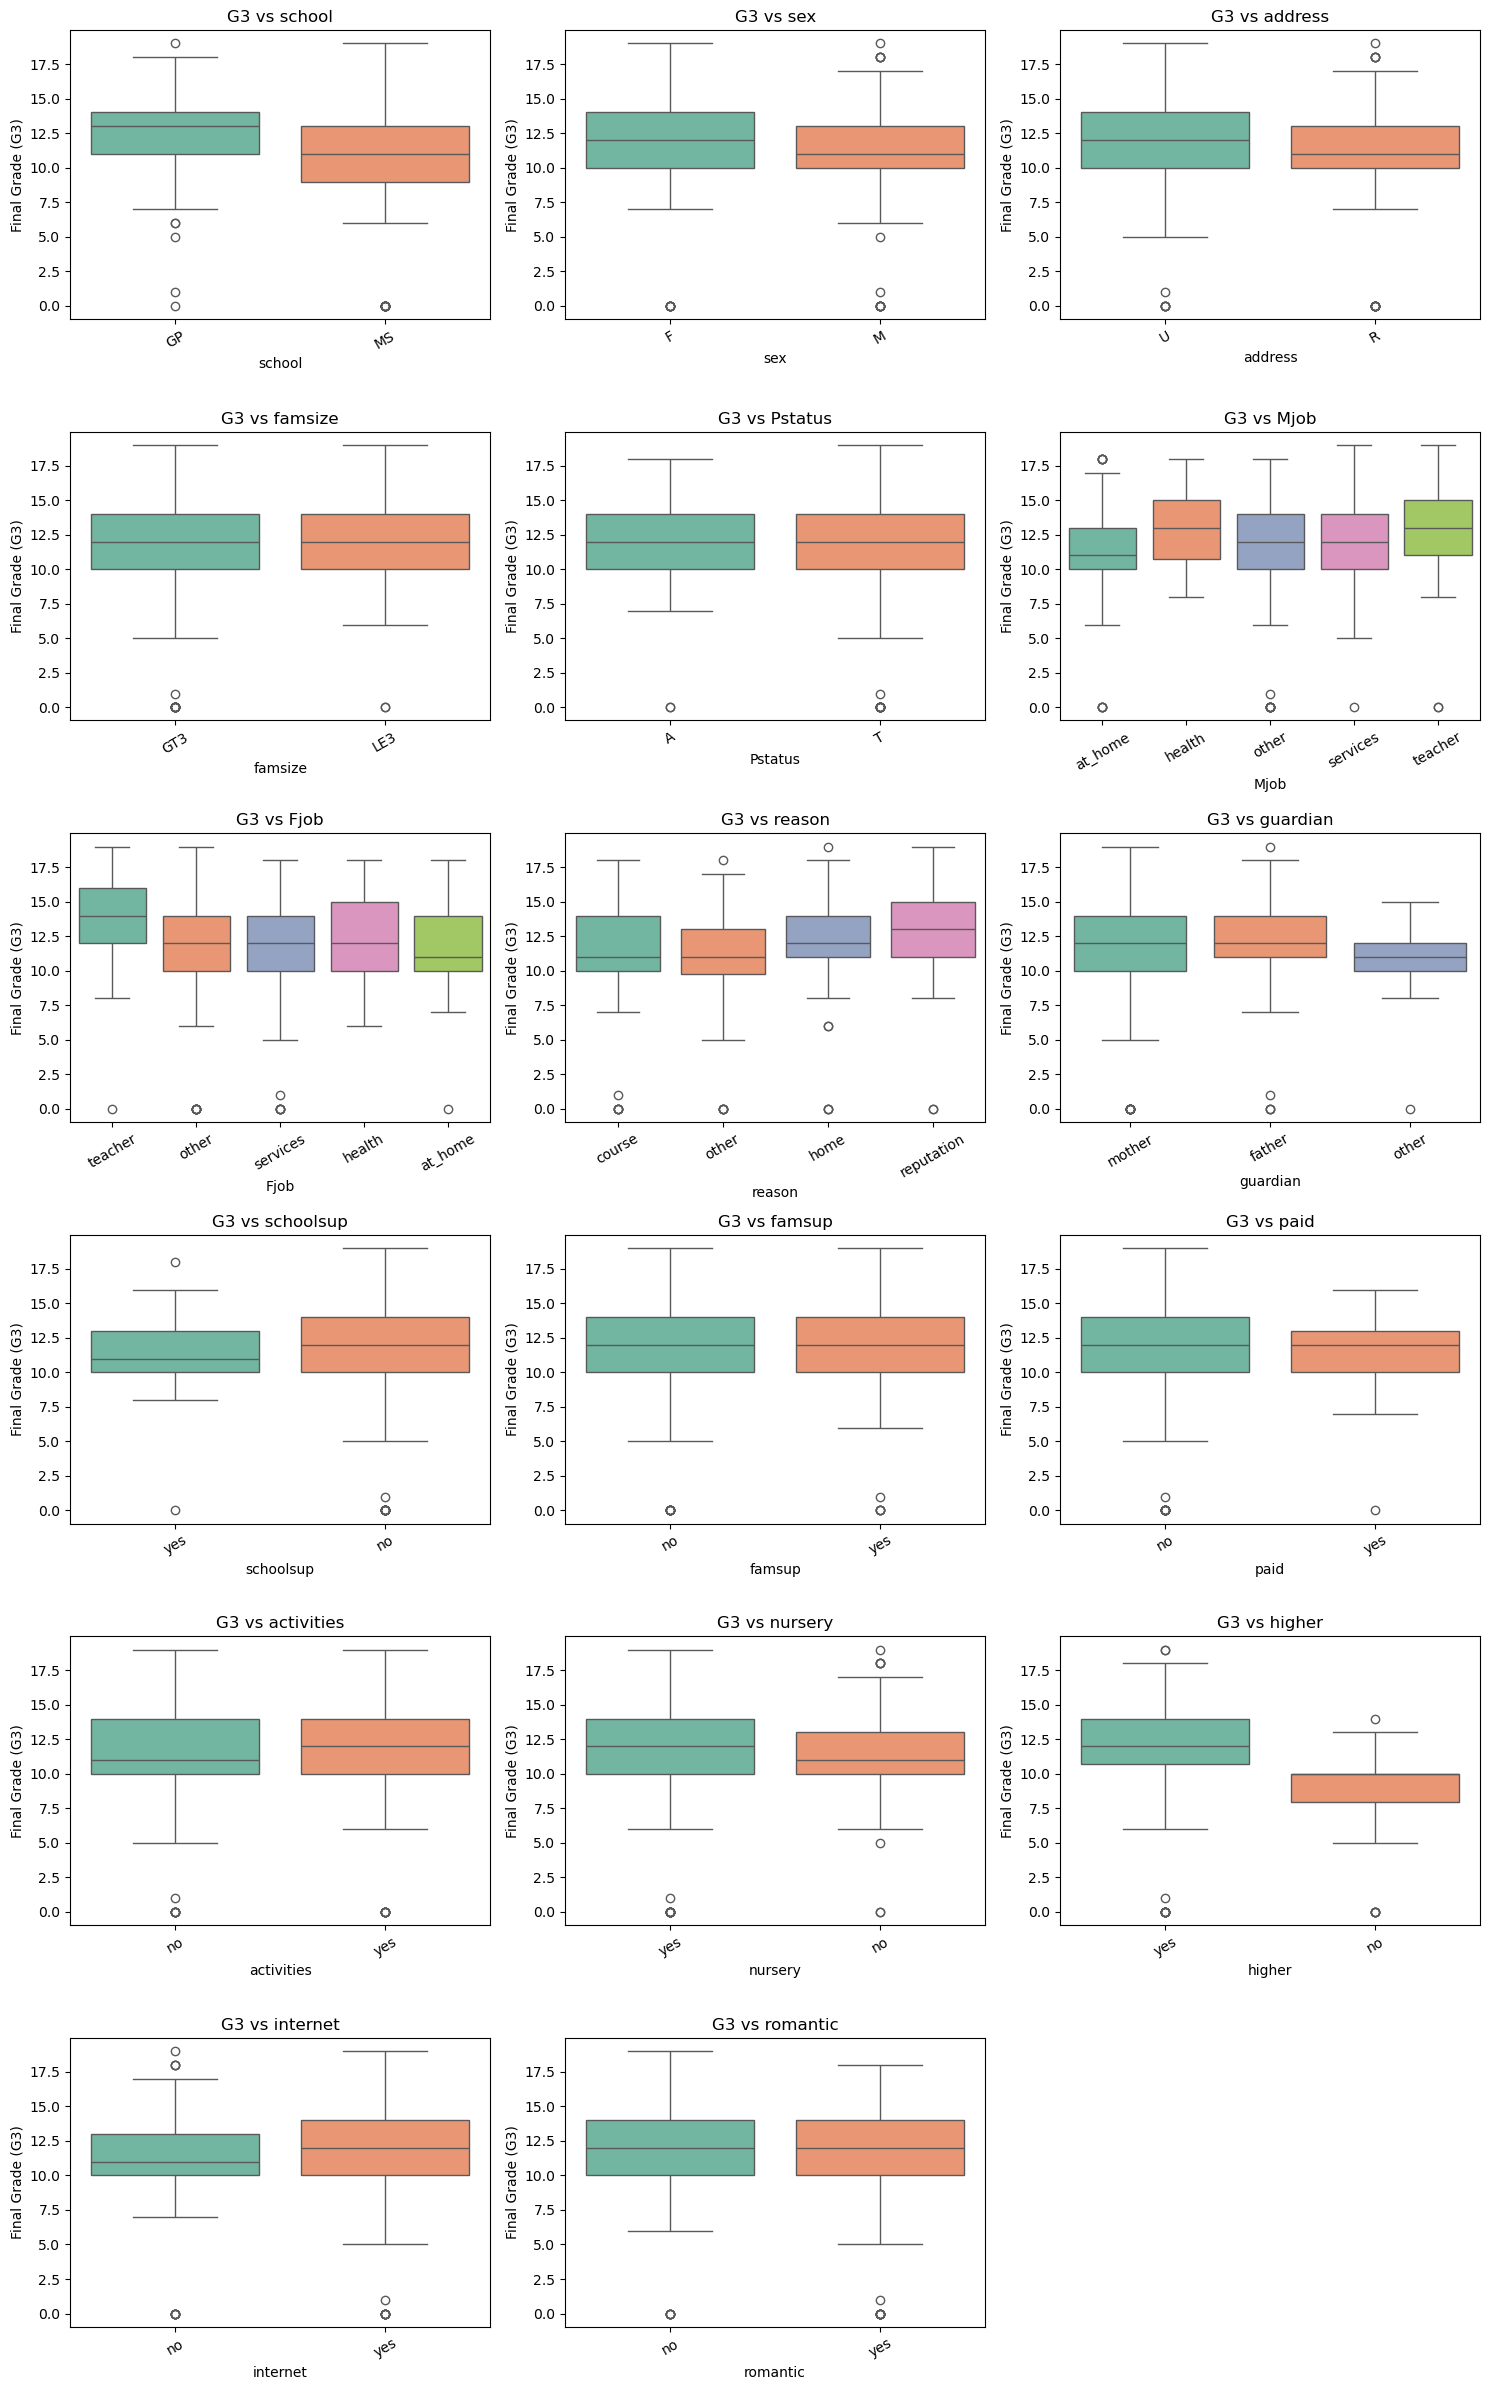

In [16]:

cat_vars = [
    'school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 
    'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 
    'nursery', 'higher', 'internet', 'romantic'
]

cols = 3
rows = math.ceil(len(cat_vars) / cols)

fig, axes = plt.subplots(rows, cols, figsize=(15, rows * 4))
axes = axes.flatten()

for i, var in enumerate(cat_vars):
    sns.boxplot(x=var, y='G3', data=df, ax=axes[i], palette='Set2')
    axes[i].set_title(f'G3 vs {var}')
    axes[i].set_xlabel(var)
    axes[i].set_ylabel('Final Grade (G3)')
    axes[i].tick_params(axis='x', rotation=30)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

Looking now at the Categorical variables, we can clearly see that: school, higher(wants to take higher education),
nursery(attended nursery school), Reason, and wether a student have access to the internet at home or not, play a role in association with G3.

Coming to the Conclusion of: **['traveltime', 'studytime', 'failures', 'famrel', 'Dalc','absences']** in addiction to : **['school','reason','nursery','higher','internet']**

Note: Comparing the Two lists: *Famrel* , *Reason* , *Nursery* are missing from the Mutual Information Score. 

Let's Use Random Forest for feature selection, and comapre the results!

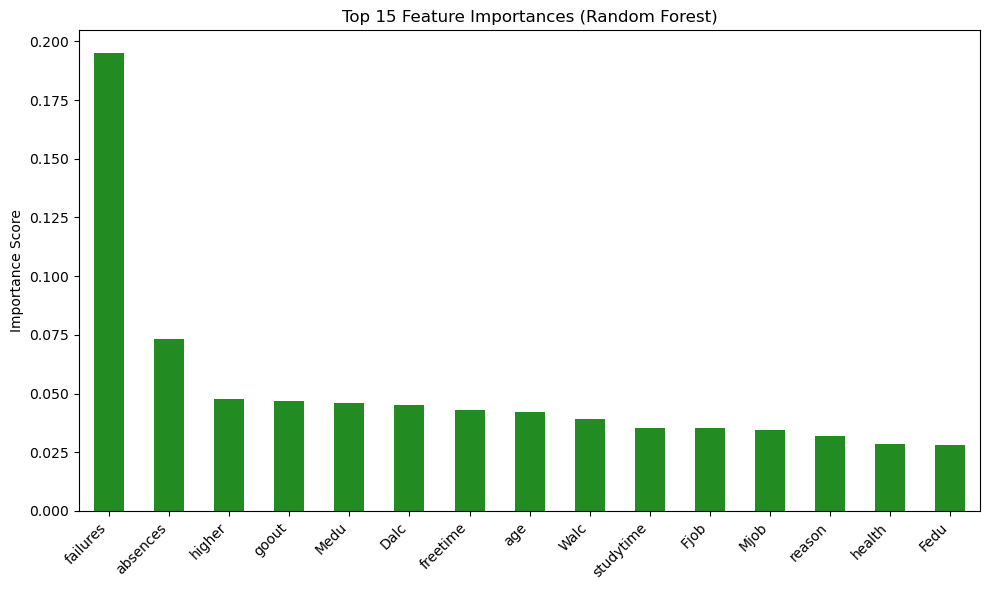

In [17]:

X_train_rf = X_train.copy()
cat_cols = X_train_rf.select_dtypes(include=['object', 'category']).columns
encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
X_train_rf[cat_cols] = encoder.fit_transform(X_train_rf[cat_cols])

rf_model = RandomForestRegressor(n_estimators=100, random_state=0)
rf_model.fit(X_train_rf, y_train)

rf_importances = pd.Series(rf_model.feature_importances_, index=X_train_rf.columns).sort_values(ascending=False)


plt.figure(figsize=(10, 6))
rf_importances.head(15).plot(kind='bar', color='forestgreen')
plt.title('Top 15 Feature Importances (Random Forest)')
plt.ylabel('Importance Score')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Random Forest evaluates feature importance under the hood (using bagging, impurity reduction, and permutation testing to handle complex non-linear relationships and interactions).

Random Forest concludes with a fair list as seen in the plot, and it indeed mentions almost the same variables as the Mutual Information and the Box plot Visualization.

Let's Try one last method, **The Lasso** to see if non useful features will shrink to 0

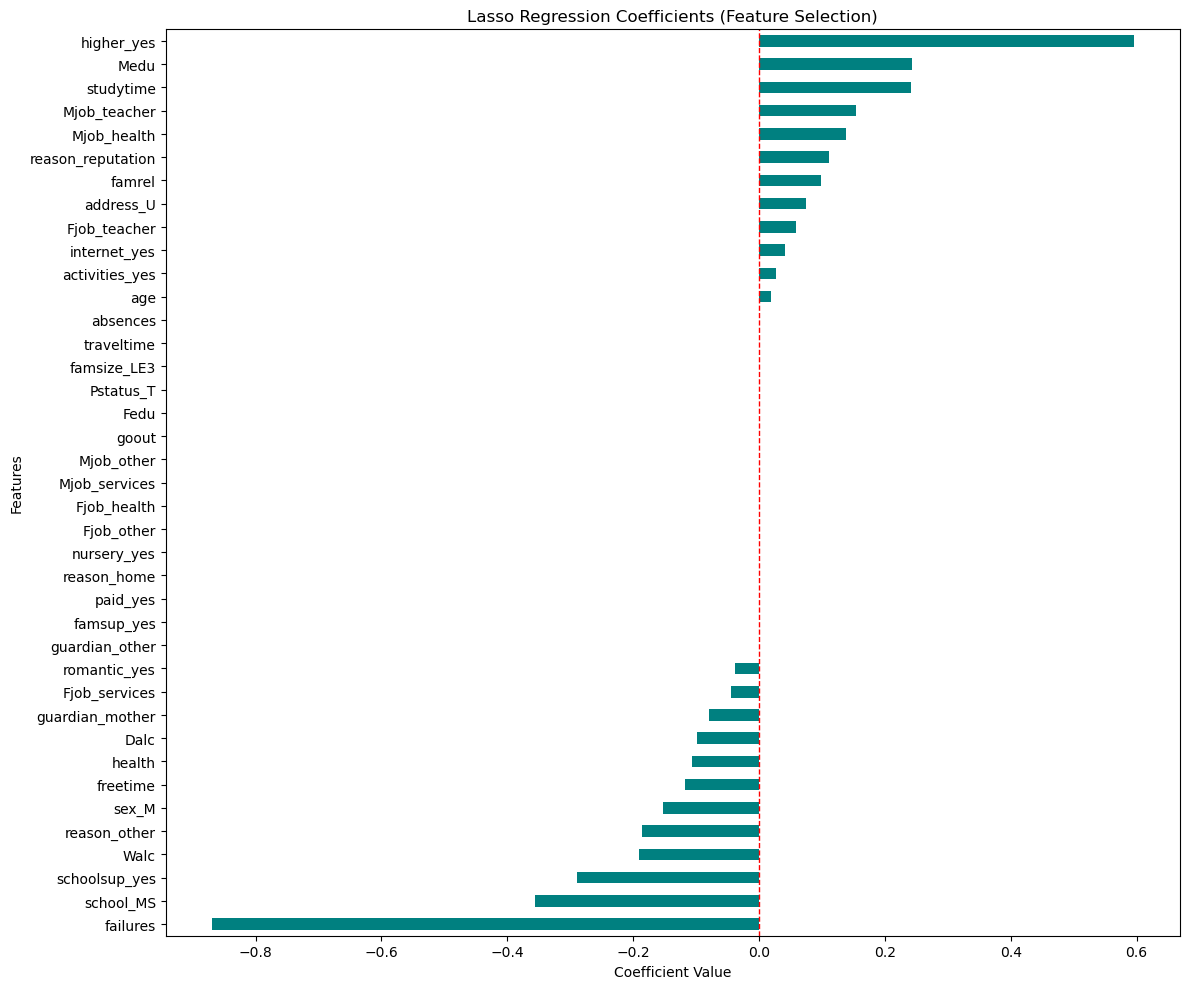

In [18]:
X_train_lasso = X_train.copy()
X_train_lasso = pd.get_dummies(X_train_lasso, drop_first=True)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_lasso)

lasso_cv = LassoCV(cv=5, random_state=0, max_iter=10000)
lasso_cv.fit(X_train_scaled, y_train)
lasso_coefs = pd.Series(lasso_cv.coef_, index=X_train_lasso.columns)


plt.figure(figsize=(12, 10))
lasso_coefs.sort_values().plot(kind='barh', color='teal')
plt.title('Lasso Regression Coefficients (Feature Selection)')
plt.xlabel('Coefficient Value')
plt.ylabel('Features')
plt.axvline(x=0, color='red', linestyle='--', linewidth=1)
plt.tight_layout()
plt.show()

In [19]:

visual_selected = [
    'traveltime', 'studytime', 'failures', 'famrel', 'Dalc', 'absences',
    'school', 'reason', 'nursery', 'higher', 'internet'
]

mi_top = list(mi_scores.index)
rf_top = list(rf_importances.index)
lasso_surviving = list(lasso_coefs[lasso_coefs != 0].index)

feature_records = []

for f in visual_selected:
    feature_records.append({'Feature': f, 'Source': 'Visual'})
for f in mi_top:
    feature_records.append({'Feature': f, 'Source': 'Mutual_Info'})
for f in rf_top:
    feature_records.append({'Feature': f, 'Source': 'Random_Forest'})
for f in lasso_surviving:
    feature_records.append({'Feature': f, 'Source': 'Lasso'})

master_df = pd.DataFrame(feature_records)
frequency_series = master_df['Feature'].value_counts()
final_features = frequency_series[frequency_series >=3].index.tolist()

print("Final Most Frequent >= 3 Features:")
print(final_features)

Final Most Frequent >= 3 Features:
['studytime', 'failures', 'famrel', 'Dalc', 'internet', 'health', 'age', 'Walc', 'freetime', 'traveltime', 'higher', 'nursery', 'reason', 'school', 'absences', 'Medu']


There is a lot of similarity between all of the methods used for feature selection. 
We can conclude now that **['studytime', 'failures', 'famrel', 'Dalc', 'internet', 'health', 'age', 'Walc', 'freetime', 'traveltime', 'higher', 'nursery', 'reason', 'school', 'absences', 'Medu']**
Are the most frequent and thus these are the ones that are going to be used for prediction.

In [26]:
%store combined_df

Stored 'combined_df' (DataFrame)
